### 0. Read data & Import lib 

In [1]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

events = duckdb.sql('SELECT * FROM "../dataset/raw/events.csv";')
inventory_items = duckdb.sql('SELECT * FROM "../dataset/raw/inventory_items.csv";')
orders =duckdb.sql("SELECT * FROM read_csv('../dataset/raw/orders.csv', types={'gender': 'VARCHAR'})")
order_items = duckdb.sql('SELECT * FROM "../dataset/raw/order_items.csv"')
users = duckdb.sql('SELECT * FROM "../dataset/raw/users.csv"')

### 1. Data Cleaning and Data Profiling & Distribution Check

#### 1.1 events

##### 1.1.1 Anonymous Traffic & Artifact Standardization

In the raw `events` data, i found two primary data quality issues during the profiling phase:
1. **Anonymous Traffic (Missing IDs):** I noticed that the data consists of a large portion of 'null' values inside a `user_id` column, which may representing guest users who browsed the platform without logging in or registering. 
2. **System Artifacts:** The `city` column contains the string literal `'null'` (text) instead of actual SQL `NULL` values, which would distort geographic aggregations.

**Data Engineering Action:**
Instead of simply dropping unregistered records, i decided using `0` to indicate `user_id` to explicitly track guest behavior and also standardized the string  `'null'` to a cleaner categorical label `'Unknown'`.

In [ ]:
clean_events= duckdb.sql("""
SELECT
    id,without logging in or registering
    COALESCE(user_id,0) AS user_id,
    sequence_number,
    session_id,
    created_at,
    ip_address,
    CASE WHEN
        city = 'null' THEN 'Unknown' ELSE
        city
    END AS city,
    state,
    postal_code,
    browser,
    traffic_source,
    uri,
    event_type
FROM events
""")

In [3]:
clean_events.to_parquet('../dataset/processed/clean_events.parquet')

##### 1.1.2 Data Profiling & Distribution Check

In [4]:
df= clean_events.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2428103 entries, 0 to 2428102
Data columns (total 13 columns):
 #   Column           Dtype         
---  ------           -----         
 0   id               int64         
 1   user_id          int64         
 2   sequence_number  int64         
 3   session_id       object        
 4   created_at       datetime64[us]
 5   ip_address       object        
 6   city             object        
 7   state            object        
 8   postal_code      object        
 9   browser          object        
 10  traffic_source   object        
 11  uri              object        
 12  event_type       object        
dtypes: datetime64[us](1), int64(3), object(9)
memory usage: 240.8+ MB


In [5]:
df.describe()

,id,user_id,sequence_number,created_at
count,2.428103e+06,2.428103e+06,2.428103e+06,2428103
mean,1.214052e+06,2.684218e+04,3.308997e+00,2023-12-15 17:19:35.396426
min,1.000000e+00,0.000000e+00,1.000000e+00,2019-01-02 00:09:00
25%,6.070265e+05,0.000000e+00,1.000000e+00,2022-04-09 04:40:00
50%,1.214052e+06,6.852000e+03,2.000000e+00,2024-06-06 23:12:15
75%,1.821078e+06,5.340900e+04,4.000000e+00,2025-12-01 11:20:34
max,2.428103e+06,1.000000e+05,1.300000e+01,2026-10-12 23:55:20.723856
std,7.009331e+05,3.265723e+04,2.667489e+00,NaN


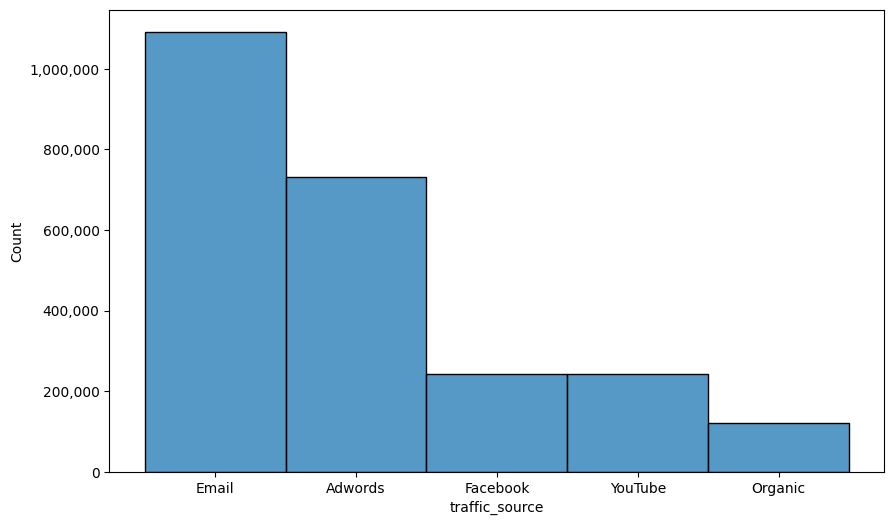

In [6]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='traffic_source')
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.show()

#### 1.2 inventory_items

##### 1.2.1 Data Sanitation: Product Metadata Imputation
During the initial data profiling, missing values (`NULL`) were detected in `product_name` and `product_brand` columns. 

**Data Engineering Action:**
To prevent data loss during downstream BI aggregations and ensure dashboard filter integrity, i changed these missing values to `'Unknown'`. This provides a distinct catch-all category for untagged inventory without distorting the overall stock value.

In [7]:
clean_inventory_items=duckdb.sql("""
SELECT
    id,
    product_id,
    created_at,
    sold_at,
    cost,
    product_category,
    COALESCE(product_name,'Unknown') AS product_name,
    COALESCE(product_brand,'Unknown') AS product_brand,
    product_retail_price,
    product_department,
    product_sku,
    product_distribution_center_id
FROM
    inventory_items
""")

In [8]:
clean_inventory_items.to_parquet('../dataset/processed/clean_inventory_items.parquet')

##### 1.2.2 Data Profiling & Distribution Check

In [9]:
df =clean_inventory_items.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 491228 entries, 0 to 491227
Data columns (total 12 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              491228 non-null  int64         
 1   product_id                      491228 non-null  int64         
 2   created_at                      491228 non-null  datetime64[us]
 3   sold_at                         181946 non-null  datetime64[us]
 4   cost                            491228 non-null  float64       
 5   product_category                491228 non-null  object        
 6   product_name                    491228 non-null  object        
 7   product_brand                   491228 non-null  object        
 8   product_retail_price            491228 non-null  float64       
 9   product_department              491228 non-null  object        
 10  product_sku                     491228 non-null  object 

In [10]:
df.describe()

,id,product_id,created_at,sold_at,cost,product_retail_price,product_distribution_center_id
count,491228.000000,491228.000000,491228,181946,491228.000000,491228.000000,491228.000000
mean,245614.500000,15300.980879,2023-12-01 04:29:34.879896,2024-11-20 16:24:22.717190,28.775064,59.819350,4.999389
min,1.000000,1.000000,2018-12-01 15:41:57,2019-01-11 18:29:44,0.008300,0.020000,1.000000
25%,122807.750000,8025.000000,2022-04-09 04:19:20.750000,2023-11-10 23:06:49.250000,11.439120,24.950001,2.000000
50%,245614.500000,16065.500000,2024-03-07 10:21:19,2025-05-22 04:26:56,19.987000,39.990002,5.000000
75%,368421.250000,22568.000000,2025-09-15 11:23:57,2026-04-24 16:45:56.500000,34.748000,69.980003,8.000000
max,491228.000000,29120.000000,2026-10-14 11:42:00.037604,2026-10-15 00:13:51.216575,557.151002,999.000000,10.000000
std,141805.453354,8417.954620,NaN,NaN,30.871576,66.622865,2.898489


In [11]:
# Time-Travel Anomaly Check
df.query("created_at > sold_at or cost > product_retail_price")

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id


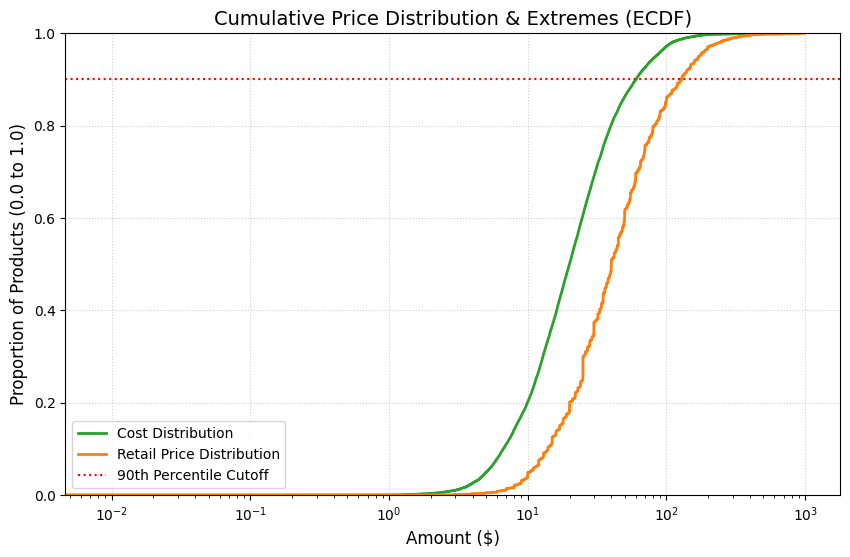

In [12]:
plt.figure(figsize=(10, 6))

sns.ecdfplot(data=df, x='cost', label='Cost Distribution', color='#2ca02c', linewidth=2)
sns.ecdfplot(data=df, x='product_retail_price', label='Retail Price Distribution', color='#ff7f0e', linewidth=2)
plt.axhline(y=0.90, color='red', linestyle=':', label='90th Percentile Cutoff')
plt.title('Cumulative Price Distribution & Extremes (ECDF)', fontsize=14)
plt.xlabel('Amount ($)', fontsize=12)
plt.ylabel('Proportion of Products (0.0 to 1.0)', fontsize=12)
plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.xscale('log')
plt.show()

#### 1.3 orders

##### 1.3.1 Data Sanitation: Temporal Casting & Pipeline Resilience
In the raw `orders` table, critical order milestone dates (`created_at`, `shipped_at`, `delivered_at`, `returned_at`) require strict data type enforcement to enable precise time-series aggregations and fulfillment latency calculations.

**Data Engineering Action:**
1. **Defensive Temporal Casting:** I using the `TRY_CAST()` instead of normal `CAST()` function to enforced `TIMESTAMP` formats, which ensure that the pipeline able to run smoothly without casusing the system interupt or failure when facing `null` value.
2. **Logic Validation:** I filtered out the "Time-Travel" anomaly (where `shipped_at < created_at`) generated by the synthetic data engine to maintain temporal integrity.

In [13]:
clean_orders= duckdb.sql("""
SELECT
    order_id,
    user_id,
    status,
    gender,
    TRY_CAST(created_at AS timestamp) AS created_at,
    TRY_CAST(returned_at AS timestamp) AS returned_at,
    TRY_CAST(shipped_at AS timestamp) AS shipped_at,
    TRY_CAST(delivered_at AS timestamp) AS delivered_at,
    num_of_item
FROM
    orders
WHERE
    shipped_at >= created_at OR shipped_at IS NULL
""")

In [14]:
clean_orders.to_parquet('../dataset/processed/clean_orders.parquet')

##### 1.3.2 Data Profiling & Distribution Check

In [15]:
df = clean_orders.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124978 entries, 0 to 124977
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_id      124978 non-null  int64         
 1   user_id       124978 non-null  int64         
 2   status        124978 non-null  object        
 3   gender        124978 non-null  object        
 4   created_at    124978 non-null  datetime64[us]
 5   returned_at   12651 non-null   datetime64[us]
 6   shipped_at    81184 non-null   datetime64[us]
 7   delivered_at  43941 non-null   datetime64[us]
 8   num_of_item   124978 non-null  int64         
dtypes: datetime64[us](4), int64(3), object(2)
memory usage: 8.6+ MB


In [16]:
df.describe()

,order_id,user_id,created_at,returned_at,shipped_at,delivered_at,num_of_item
count,124978.000000,124978.000000,124978,12651,81184,43941,124978.000000
mean,62489.500000,50094.584863,2024-11-15 06:58:47.877269,2024-11-28 05:52:01.672567,2024-11-16 18:43:56.026773,2024-11-21 09:07:10.266143,1.451984
min,1.000000,2.000000,2019-01-05 20:04:52,2019-02-13 21:22:23,2019-01-08 02:43:52,2019-01-10 23:55:52,1.000000
25%,31245.250000,25180.500000,2023-11-02 20:07:01.250000,2023-11-23 15:19:00,2023-11-04 07:42:01,2023-11-09 16:29:12,1.000000
50%,62489.500000,50213.000000,2025-05-17 17:18:01.500000,2025-05-31 03:11:28,2025-05-19 19:31:31.500000,2025-05-27 13:25:34,1.000000
75%,93733.750000,75002.750000,2026-04-21 03:53:44.750000,2026-04-29 08:34:28,2026-04-21 18:05:44.500000,2026-04-25 11:49:11,2.000000
max,124978.000000,100000.000000,2026-10-09 00:34:14.224402,2026-10-18 16:32:27.983876,2026-10-11 22:37:53,2026-10-16 18:37:27.769125,4.000000
std,36078.185309,28812.572108,NaN,NaN,NaN,NaN,0.805468


In [17]:
return_rate = 100.0 * df['returned_at'].count() / df['created_at'].count()
print(f"This dataset consists of {df['order_id'].count()} records and the return rate is {return_rate:.3f}%")

This dataset consists of 124978 records and the return rate is 10.123%


In [18]:
#==========================================
# Logical Outliers Check
#==========================================
df.query("" \
"   created_at > returned_at or " \
"   created_at > shipped_at or " \
"   created_at > delivered_at"
)

,order_id,user_id,status,gender,created_at,returned_at,shipped_at,delivered_at,num_of_item


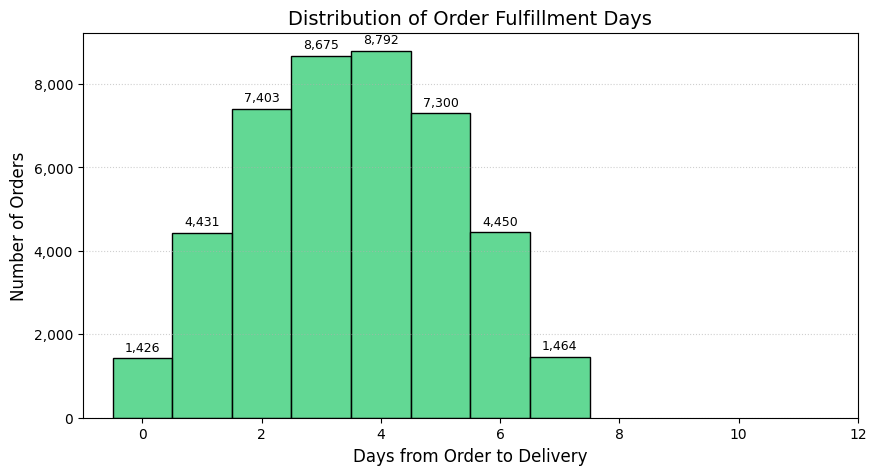

In [19]:
df['created_at'] = pd.to_datetime(df['created_at'])
df['delivered_at'] = pd.to_datetime(df['delivered_at'])

df['fulfillment_days'] = (df['delivered_at'] - df['created_at']).dt.days

valid_delivery = df[(df['fulfillment_days'].notnull()) & (df['fulfillment_days'] >= 0)]

plt.figure(figsize=(10, 5))

sns.histplot(data=valid_delivery, x='fulfillment_days', discrete=True, color='#2ecc71')
plt.title('Distribution of Order Fulfillment Days', fontsize=14)
plt.xlabel('Days from Order to Delivery', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xlim(-1, 12)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():,.0f}', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 3), textcoords='offset points')
    
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

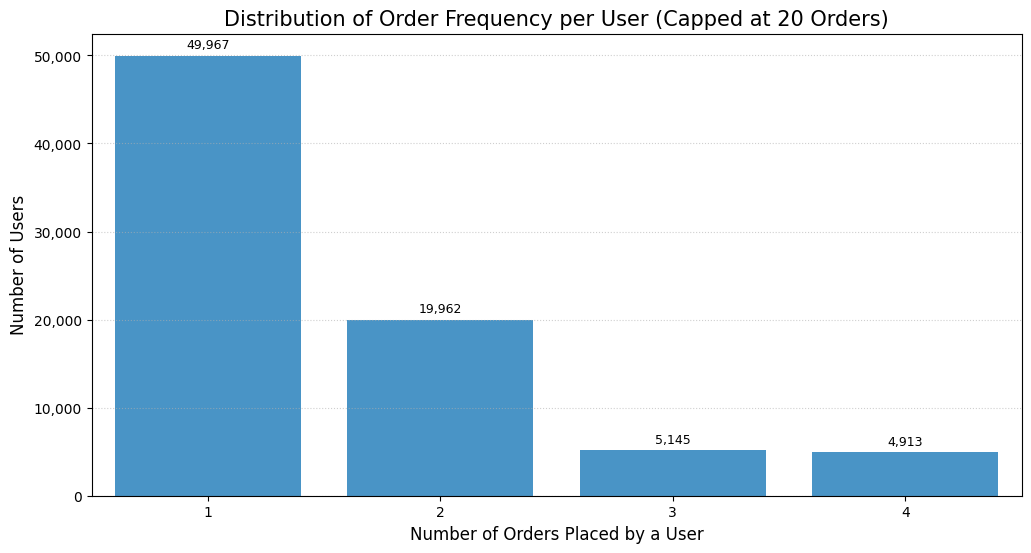

In [20]:
orders_per_user = df.groupby('user_id')['order_id'].nunique().reset_index(name='order_count')
plt.figure(figsize=(12, 6))

sns.countplot(
    data=orders_per_user[orders_per_user['order_count'] <= 20], 
    x='order_count', 
    color='#3498db'
)

plt.title('Distribution of Order Frequency per User (Capped at 20 Orders)', fontsize=15)
plt.xlabel('Number of Orders Placed by a User', fontsize=12)
plt.ylabel('Number of Users', fontsize=12)

plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():,.0f}', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 3), textcoords='offset points')

plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

#### 1.4 order_items

##### 1.4.1 Diagnostic

In [21]:
df= order_items.df()
df.query("" \
"   created_at > returned_at or " \
"   created_at > shipped_at or " \
"   created_at > delivered_at"
)

,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
1,150932,103936,83088,14235,407383,Shipped,2023-12-01 12:19:42,2023-11-29 19:00:59,NaT,NaT,0.02
4,28607,19698,15873,14159,77011,Complete,2023-07-31 03:59:03,2023-07-29 07:27:02,2023-07-30 11:51:02,NaT,0.49
5,44196,30424,24525,14159,119038,Shipped,2024-01-28 23:45:56,2024-01-27 11:26:47,NaT,NaT,0.49
6,81009,55722,44877,14159,218582,Shipped,2025-06-21 20:05:15,2025-06-20 13:25:42,NaT,NaT,0.49
13,10574,7338,5877,14202,28431,Complete,2023-08-23 01:44:35,2023-08-22 11:08:49,2023-08-25 17:57:49,NaT,1.50
...,...,...,...,...,...,...,...,...,...,...,...
181436,151263,104156,83266,23951,408278,Shipped,2024-12-05 14:38:32,2024-12-03 18:39:01,NaT,NaT,903.00
181438,164892,113492,90668,23654,445090,Shipped,2024-02-25 00:09:03,2024-02-23 06:22:44,NaT,NaT,903.00
181446,32769,22568,18151,24341,88221,Shipped,2025-03-17 22:58:50,2025-03-17 09:38:20,NaT,NaT,950.00
181451,111391,76583,61461,24110,300706,Shipped,2025-01-25 13:12:02,2025-01-24 01:19:46,NaT,NaT,990.00


In [22]:
duckdb.sql("""
SELECT
    MAX(created_at) - MAX(returned_at),
    MAX(created_at) - MAX(shipped_at),
    MAX(created_at) - MAX(delivered_at)
FROM
    order_items
WHERE
    created_at > returned_at or
    created_at > shipped_at or
    created_at > delivered_at
""")

┌──────────────────────────────────────┬─────────────────────────────────────┬───────────────────────────────────────┐
│ (max(created_at) - max(returned_at)) │ (max(created_at) - max(shipped_at)) │ (max(created_at) - max(delivered_at)) │
│               interval               │              interval               │               interval                │
├──────────────────────────────────────┼─────────────────────────────────────┼───────────────────────────────────────┤
│ -4 days -17:05:35.14024              │ 1 day 02:42:30.176495               │ -3 days -05:10:12.14024               │
└──────────────────────────────────────┴─────────────────────────────────────┴───────────────────────────────────────┘

**Issue Identified:** 
- During EDA phase, logical chronological validation (created_at > shipped_at | delivered_at) show that 35,889 rows of dirty data in the `order_items` table that severely violate standard time sequencing.

**Diagnostic Analysis:** 
- Through time-gap investigation (with some inverted discrepancies exceeding 40 hours), the hypothesis of unaligned timezone offsets across cross-border business systems was ruled out. The most likely explanation is an inconsistency in how the (synthetic) source data was generated.

**Data Cleaning Strategy:** 
- Because the downstream Mart_Logistics_Experience requires calculating actual fulfillment duration, retaining these anomalies would lead to "negative" logistics fulfillment times, which would distort the fulfilment-time analysis. Thus, i removed these data from table but store in `exception_order_items` table during the ELT transformation phase.

In [23]:
exception_order_items = duckdb.sql("""
SELECT
    id,
    order_id,
    user_id,
    inventory_item_id,
    status,
    TRY_CAST(created_at AS timestamp) AS created_at,
    TRY_CAST(shipped_at AS timestamp) AS shipped_at,
    TRY_CAST(delivered_at AS timestamp) AS delivered_at,
    TRY_CAST(returned_at AS timestamp) AS returned_at,
    sale_price
FROM order_items
WHERE 
        created_at > returned_at or 
        created_at > shipped_at or 
        created_at > delivered_at
""")

In [24]:
exception_order_items.to_parquet('../dataset/processed/exception_order_items.parquet')

In [25]:
clean_order_items = duckdb.sql("""
SELECT
    id,
    order_id,
    user_id,
    inventory_item_id,
    status,
    TRY_CAST(created_at AS timestamp) AS created_at,
    TRY_CAST(shipped_at AS timestamp) AS shipped_at,
    TRY_CAST(delivered_at AS timestamp) AS delivered_at,
    TRY_CAST(returned_at AS timestamp) AS returned_at,
    sale_price
FROM order_items
WHERE 
    (created_at <= shipped_at OR shipped_at IS NULL) AND
    (created_at <= delivered_at OR delivered_at IS NULL) AND
    (created_at <= returned_at OR returned_at IS NULL)
""")

In [26]:
clean_order_items.to_parquet('../dataset/processed/clean_order_items.parquet')

##### 1.4.2 Data Profiling & Distribution Check

In [27]:
clean_df= clean_order_items.df()
except_df = exception_order_items.df()
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145577 entries, 0 to 145576
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   id                 145577 non-null  int64         
 1   order_id           145577 non-null  int64         
 2   user_id            145577 non-null  int64         
 3   inventory_item_id  145577 non-null  int64         
 4   status             145577 non-null  object        
 5   created_at         145577 non-null  datetime64[us]
 6   shipped_at         82141 non-null   datetime64[us]
 7   delivered_at       44457 non-null   datetime64[us]
 8   returned_at        12765 non-null   datetime64[us]
 9   sale_price         145577 non-null  float64       
dtypes: datetime64[us](4), float64(1), int64(4), object(1)
memory usage: 11.1+ MB


In [28]:
except_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35889 entries, 0 to 35888
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 35889 non-null  int64         
 1   order_id           35889 non-null  int64         
 2   user_id            35889 non-null  int64         
 3   inventory_item_id  35889 non-null  int64         
 4   status             35889 non-null  object        
 5   created_at         35889 non-null  datetime64[us]
 6   shipped_at         35889 non-null  datetime64[us]
 7   delivered_at       19310 non-null  datetime64[us]
 8   returned_at        5572 non-null   datetime64[us]
 9   sale_price         35889 non-null  float64       
dtypes: datetime64[us](4), float64(1), int64(4), object(1)
memory usage: 2.7+ MB


In [29]:
print(f"raw order_items                           :{order_items.shape[0]} records \nclean_order_items + exception_order_items :{except_df.shape[0] + clean_df.shape[0]} records")
assert order_items.shape[0] == clean_df.shape[0] + except_df.shape[0], \
    "Reconciliation failed: record counts do not match!"

print("Reconciliation passed!")

raw order_items                           :181466 records 
clean_order_items + exception_order_items :181466 records
Reconciliation passed!


In [30]:
print(f"clean_order_items table remains {clean_df.shape[0]} records, exception_order_items table consists of {except_df.shape[0]} records")

clean_order_items table remains 145577 records, exception_order_items table consists of 35889 records


In [31]:
abnormal_proportion = round(
    100.0 * except_df.shape[0] / order_items.shape[0],
    2
)
print(f"Abnormal proportion: {abnormal_proportion}%")

Abnormal proportion: 19.78%


#### 1.5 users

##### 1.5.1 Data Sanitation: Product Metadata Imputation
During the profiling of user demographics, i used different imputation strategy based on their own feature to protect downstream analytical integrity:

1. **Categorical Artifact Standardization:** Missing values in standard text-based fields like `email`, `gender`, `street_address` and system artifacts (e.g., the literal string `'null'` in `city`) were systematically standardized to `'Unknown'`. This guarantees clean aggregations and filtering in BI dimensions.
2. **Strategic Null Preservation:** For numerical (`age`) and temporal fields (`created_at`), i remain those fields as `NULL` values. Because imputing `age` with `0` or mean values would severely distort demographic statistical distributions and cohort analyses.

In [32]:
clean_users= duckdb.sql("""
SELECT
    id,
    first_name,
    last_name,
    COALESCE(email,'Unknown') AS email,
    COALESCE(age,null) AS age,
    COALESCE(gender,'Unknown') AS gender,
    state,
    COALESCE(street_address,'Unknown') AS street_address,
    postal_code,
    COALESCE(NULLIF(LOWER(city), 'null'), 'Unknown') AS city,
    country,
    latitude,
    longitude,
    traffic_source,
    COALESCE(created_at,null) AS created_at,
    user_geom
FROM users
""")

In [33]:
clean_users.to_parquet('../dataset/processed/clean_users.parquet')

##### 1.5.2 Data Profiling & Distribution Check

In [34]:
df= clean_users.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   id              100000 non-null  int64         
 1   first_name      100000 non-null  object        
 2   last_name       100000 non-null  object        
 3   email           100000 non-null  object        
 4   age             100000 non-null  int64         
 5   gender          100000 non-null  object        
 6   state           100000 non-null  object        
 7   street_address  100000 non-null  object        
 8   postal_code     100000 non-null  object        
 9   city            100000 non-null  object        
 10  country         100000 non-null  object        
 11  latitude        100000 non-null  float64       
 12  longitude       100000 non-null  float64       
 13  traffic_source  100000 non-null  object        
 14  created_at      100000 non-null  date

In [35]:
print(f"Extreme value of age is {df['age'].min()} and {df['age'].max() } year old")

Extreme value of age is 12 and 70 year old
